# OULAD Growth Analytics — Funnel, Cohort Retention & the Early-Engagement "Magic Moment"
**Real data:** Open University Learning Analytics Dataset (Kuzilek, Hlosta & Zdrahal, 2017, *Scientific Data* 4:170171), CC BY 4.0.
32,593 student × module-presentation enrolments, 7 modules, 4 presentations (2013B, 2013J, 2014B, 2014J; B = February start, J = October start).

Funnel: **Registered → First VLE activity → First assessment submitted → Passed (Pass/Distinction)**; withdrawal = churn.
Section 6 is the only place that uses **hypothetical** money assumptions (`assumptions/`), kept apart from the real findings.

In [1]:
import sys, sqlite3, pandas as pd, numpy as np
import plotly.express as px, plotly.graph_objects as go, plotly.io as pio
from plotly.subplots import make_subplots
from pathlib import Path
sys.path.insert(0, "../sql"); import run_queries as rq
pio.renderers.default = "plotly_mimetype+png"; pio.templates.default = "plotly_white"
ASSETS = Path("../assets"); ASSETS.mkdir(exist_ok=True)
BRAND = ["#4F46E5", "#06B6D4", "#10B981", "#F59E0B", "#EF4444", "#8B5CF6"]
conn = sqlite3.connect(":memory:"); rq.load(conn)
Q = rq.run_all(conn, quiet=True)          # every named SQL query, as DataFrames
df = pd.read_csv("../data/student_journey.csv"); wk = pd.read_csv("../data/vle_weekly.csv")
def save(fig, name, w=1100, h=550): fig.write_image(ASSETS / f"{name}.png", width=w, height=h, scale=2)
print(df.shape, "| queries:", list(Q)); df.head()

(32593, 34) | queries: ['retention_by_presentation', 'feb_vs_oct_start', 'retention_curve_by_presentation', 'withdrawal_timing', 'magic_moment_active_days_first_14', 'magic_moment_clicks_first_28_quintiles', 'first_assessment_score_vs_outcome', 'overall_funnel', 'biggest_leak', 'final_result_mix', 'submitted_but_not_passed', 'funnel_by_module', 'segment_conversion', 'registration_timing', 'hypothetical_ltv_cac_by_imd_band']


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,...,active_days_d0_27,first_submission_day,n_assessments_submitted,mean_score,first_assessment_score,start_month,has_vle_activity,submitted_assessment,passed,withdrawn
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,...,7,18.0,5,82.0,78.0,October,1,1,1,0
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,...,11,22.0,5,66.4,70.0,October,1,1,1,0
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,...,6,NaN,0,NaN,NaN,October,1,0,0,1
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,...,16,17.0,5,76.0,72.0,October,1,1,1,0
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,...,16,26.0,5,54.4,69.0,October,1,1,1,0


## 1. Data overview

In [2]:
df.groupby(['code_module','code_presentation']).size().unstack().fillna(0).astype(int)

code_presentation,2013B,2013J,2014B,2014J
code_module,,,,
AAA,0,383,0,365
BBB,1767,2237,1613,2292
CCC,0,0,1936,2498
DDD,1303,1938,1228,1803
EEE,0,1052,694,1188
FFF,1614,2283,1500,2365
GGG,0,952,833,749


In [3]:
Q['final_result_mix']

,final_result,students,pct
0,Pass,12361,37.9
1,Withdrawn,10156,31.2
2,Fail,7052,21.6
3,Distinction,3024,9.3


## 2. Funnel — where is the biggest leak?

,step,stage,students,pct_of_registered,step_conversion_pct,students_lost
0,1,Registered,32593,100.0,NaN,NaN
1,2,First VLE activity,29228,89.7,89.7,3365.0
2,3,First assessment submitted,25843,79.3,88.4,3385.0
3,4,Passed (Pass/Distinction),15385,47.2,59.5,10458.0


,transition,lost,drop_pct,leak_rank
0,First assessment submitted -> Passed (Pass/Dis...,10458,40.5,1
1,First VLE activity -> First assessment submitted,3385,11.6,2
2,Registered -> First VLE activity,3365,10.3,3


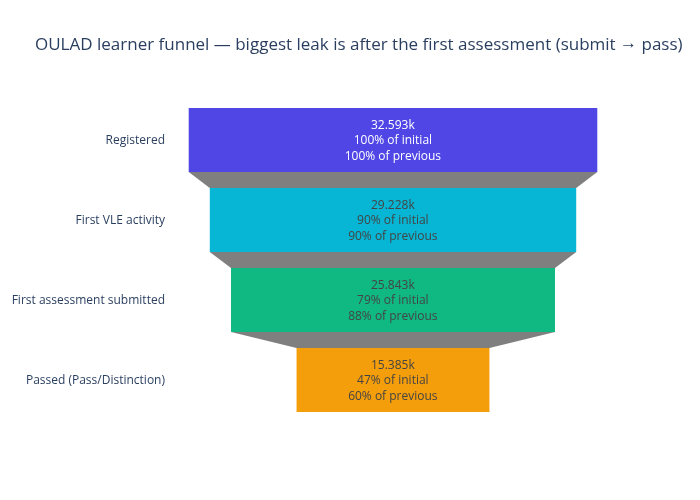

In [4]:
f = Q['overall_funnel']; display(f); display(Q['biggest_leak'])
fig = go.Figure(go.Funnel(y=f.stage, x=f.students, textinfo="value+percent initial+percent previous", marker_color=BRAND[:4]))
fig.update_layout(title="OULAD learner funnel — biggest leak is after the first assessment (submit → pass)")
save(fig, "01_funnel"); fig.show()

/tmp/ipykernel_846941/1537612972.py:1: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  m = df.groupby(['code_module','final_result']).size().unstack(); m = m.div(m.sum(1), axis=0)*100


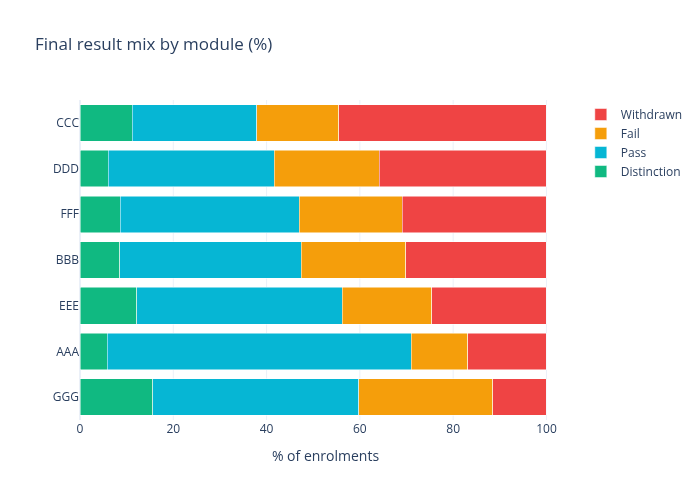

,code_module,registered,reg_to_submit_pct,submit_to_pass_pct,pass_rate_pct,withdrawal_pct,pass_rank
0,AAA,748,94.3,75.3,71.0,16.8,1
1,GGG,2534,83.3,71.7,59.7,11.5,2
2,EEE,2934,78.3,71.8,56.2,24.6,3
3,BBB,7909,76.8,61.8,47.5,30.2,4
4,FFF,7762,81.1,58.0,47.0,31.0,5
5,DDD,6272,78.8,52.8,41.6,35.9,6
6,CCC,4434,77.0,49.2,37.8,44.5,7


In [5]:
m = df.groupby(['code_module','final_result']).size().unstack(); m = m.div(m.sum(1), axis=0)*100
m = m[['Distinction','Pass','Fail','Withdrawn']].sort_values('Withdrawn')
fig = go.Figure([go.Bar(y=m.index, x=m[c], name=c, orientation='h', marker_color=col)
                 for c, col in zip(m.columns, [BRAND[2], BRAND[1], BRAND[3], BRAND[4]])])
fig.update_layout(barmode='stack', title='Final result mix by module (%)', xaxis_title='% of enrolments')
save(fig, "02_outcomes_by_module"); fig.show(); Q['funnel_by_module']

## 3. Cohort retention by presentation

,code_presentation,start_month,registered,d0_pct,d30_pct,d60_pct,d90_pct,d180_pct,pass_pct
0,2013B,February,4684,93.9,87.8,83.8,80.8,73.9,44.7
1,2013J,October,8845,89.3,86.5,84.0,82.2,75.4,50.6
2,2014B,February,7804,87.5,83.3,79.3,76.6,69.6,43.0
3,2014J,October,11260,92.0,81.7,78.3,75.8,68.6,48.5


,start_month,registered,d30_pct,d90_pct,d180_pct,withdrawal_pct
0,February,12488,84.9,78.1,71.2,31.7
1,October,20105,83.8,78.6,71.5,30.8


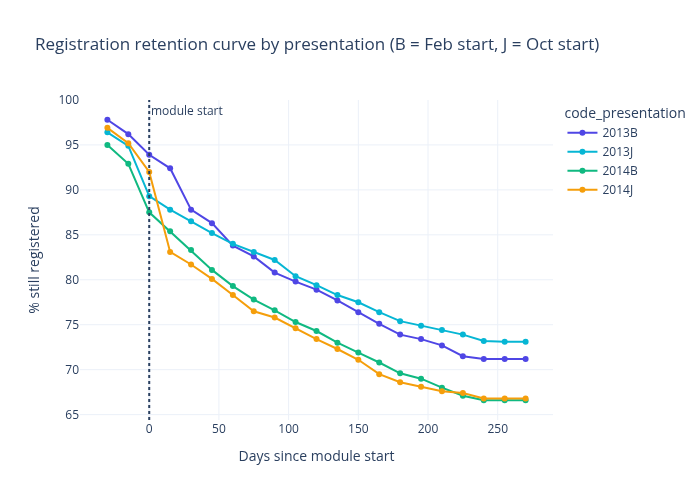

In [6]:
display(Q['retention_by_presentation']); display(Q['feb_vs_oct_start'])
rc = Q['retention_curve_by_presentation']
fig = px.line(rc, x='day_since_start', y='retained_pct', color='code_presentation', markers=True, color_discrete_sequence=BRAND,
              title='Registration retention curve by presentation (B = Feb start, J = Oct start)',
              labels={'day_since_start':'Days since module start','retained_pct':'% still registered'})
fig.add_vline(x=0, line_dash='dot', annotation_text='module start')
save(fig, "03_retention_curves"); fig.show()

,window,withdrawals,pct,cumulative_pct
0,a) before start,2678,26.6,26.6
1,b) day 0-30,2449,24.3,50.9
2,c) day 31-90,1904,18.9,69.8
3,d) day 91-180,2287,22.7,92.5
4,e) day 181+,754,7.5,100.0


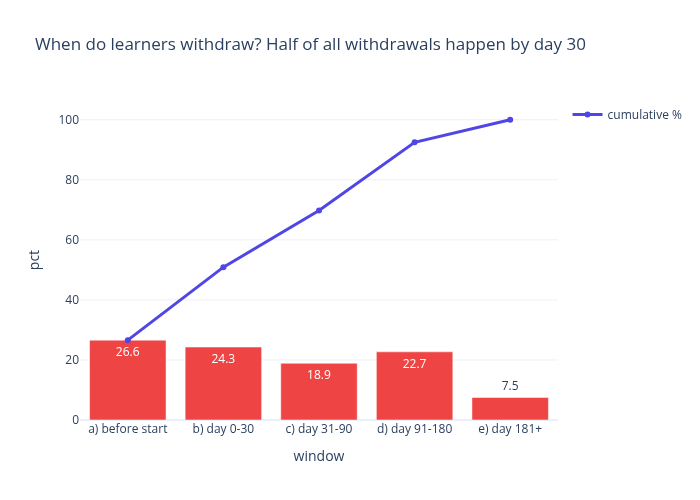

In [7]:
w = Q['withdrawal_timing']; display(w)
fig = px.bar(w, x='window', y='pct', text='pct', color_discrete_sequence=[BRAND[4]],
             title='When do learners withdraw? Half of all withdrawals happen by day 30')
fig.add_scatter(x=w.window, y=w.cumulative_pct, mode='lines+markers', name='cumulative %', line=dict(color=BRAND[0], width=3))
save(fig, "04_withdrawal_timing"); fig.show()

## 4. Looking for a magic moment (early VLE engagement)
Among learners still registered at day 14 / day 28.

,active_days_first_14,students,pass_pct,withdrawal_pct,pass_jump_pts
0,0,2760,27.7,28.1,NaN
1,1,2905,39.9,23.8,12.2
2,2,2887,45.0,22.1,5.1
3,3,2974,52.2,21.1,7.2
4,4,2652,53.1,21.2,0.9
5,5,2405,57.5,20.2,4.4
6,6,2114,59.2,19.6,1.7
7,7,1974,62.6,19.5,3.4
8,8,1650,65.4,17.7,2.8
9,9,1406,69.2,15.6,3.8


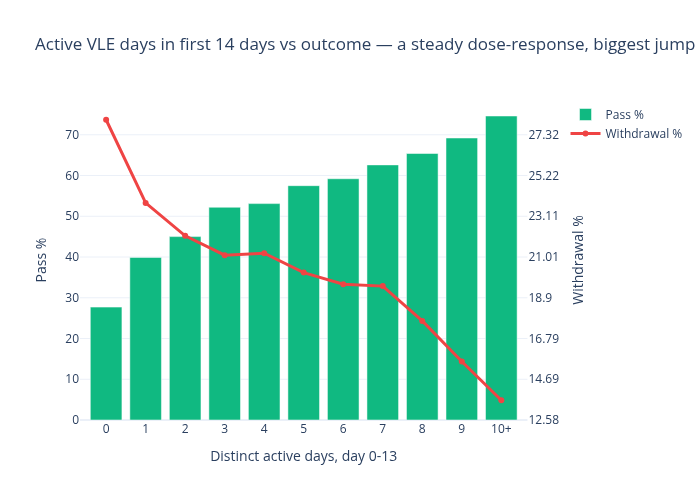

In [8]:
mm = Q['magic_moment_active_days_first_14']; display(mm)
fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_bar(x=mm.active_days_first_14, y=mm.pass_pct, name='Pass %', marker_color=BRAND[2])
fig.add_scatter(x=mm.active_days_first_14, y=mm.withdrawal_pct, name='Withdrawal %', mode='lines+markers', line=dict(color=BRAND[4], width=3), secondary_y=True)
fig.update_layout(title='Active VLE days in first 14 days vs outcome — a steady dose-response, biggest jump is 0 → 1 day',
                  xaxis_title='Distinct active days, day 0-13')
fig.update_yaxes(title_text='Pass %', secondary_y=False); fig.update_yaxes(title_text='Withdrawal %', secondary_y=True)
save(fig, "05_magic_moment_active_days"); fig.show()

,quintile,students,min_clicks,max_clicks,pass_pct,withdrawal_pct
0,1,5508,0,48,35.4,22.0
1,2,5508,49,127,49.6,21.0
2,3,5508,127,236,56.6,19.3
3,4,5507,236,433,64.1,17.2
4,5,5507,433,6084,73.6,13.3


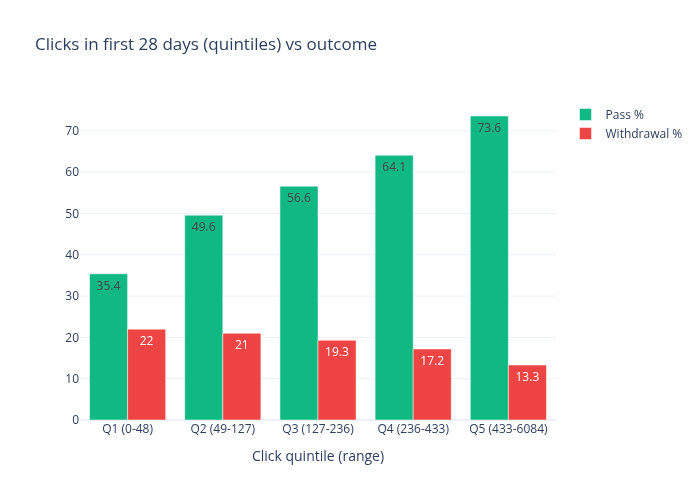

In [9]:
qn = Q['magic_moment_clicks_first_28_quintiles']; display(qn)
qn['label'] = 'Q' + qn.quintile.astype(str) + ' (' + qn.min_clicks.astype(str) + '-' + qn.max_clicks.astype(str) + ')'
fig = go.Figure([go.Bar(x=qn.label, y=qn.pass_pct, name='Pass %', marker_color=BRAND[2], text=qn.pass_pct),
                 go.Bar(x=qn.label, y=qn.withdrawal_pct, name='Withdrawal %', marker_color=BRAND[4], text=qn.withdrawal_pct)])
fig.update_layout(barmode='group', title='Clicks in first 28 days (quintiles) vs outcome', xaxis_title='Click quintile (range)')
save(fig, "06_clicks_quintiles"); fig.show()

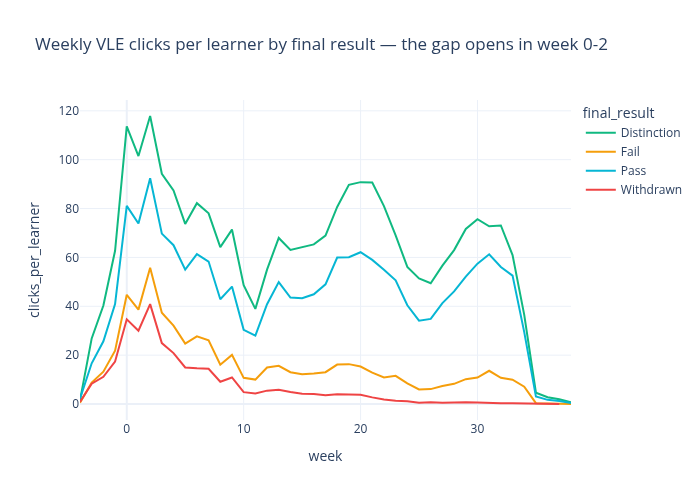

In [10]:
w2 = wk[(wk.week >= -4) & (wk.week <= 38)].groupby(['final_result','week']).agg(clicks=('clicks','sum')).reset_index()
n = df.final_result.value_counts(); w2['clicks_per_learner'] = w2.clicks / w2.final_result.map(n)
fig = px.line(w2, x='week', y='clicks_per_learner', color='final_result', color_discrete_map={'Distinction':BRAND[2],'Pass':BRAND[1],'Fail':BRAND[3],'Withdrawn':BRAND[4]},
              title='Weekly VLE clicks per learner by final result — the gap opens in week 0-2')
save(fig, "07_weekly_clicks_by_result"); fig.show()

,first_score,students,pass_pct,withdrawal_pct
0,a) <40,1632,32.8,39.3
1,b) 40-59,3062,33.3,27.8
2,c) 60-79,9601,56.5,18.6
3,d) 80+,11525,72.9,12.1


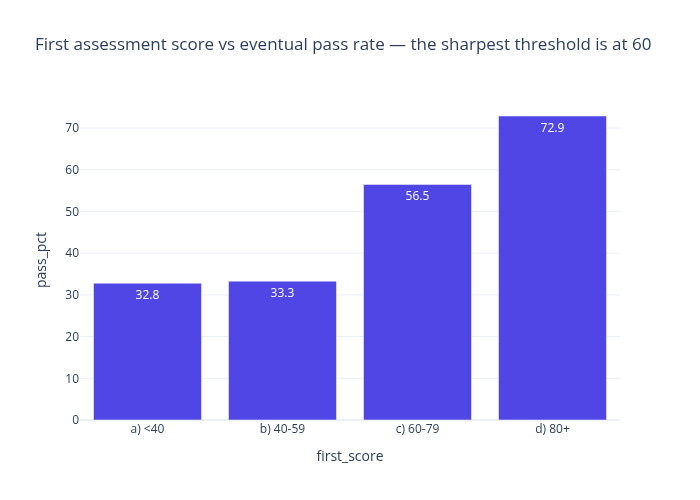

In [11]:
fs = Q['first_assessment_score_vs_outcome']; fs = fs[fs.first_score != 'no score']; display(fs)
fig = px.bar(fs, x='first_score', y='pass_pct', text='pass_pct', color_discrete_sequence=[BRAND[0]],
             title='First assessment score vs eventual pass rate — the sharpest threshold is at 60')
save(fig, "08_first_score"); fig.show()

## 5. Segments (instead of marketing channels)

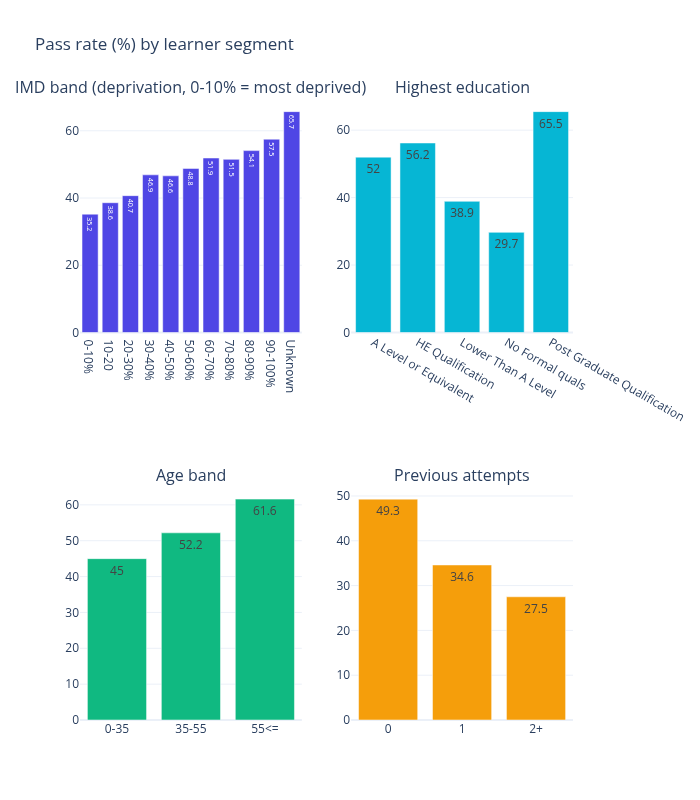

,dimension,segment,students,submit_pct,pass_pct,withdrawal_pct,rank_in_dimension,pts_vs_dimension_avg
0,age_band,55<=,216,86.6,61.6,25.0,1,8.7
1,age_band,35-55,9433,81.7,52.2,28.8,2,-0.7
2,age_band,0-35,22944,78.2,45.0,32.2,3,-7.9
3,highest_education,Post Graduate Qualification,313,89.5,65.5,23.6,1,17.0
4,highest_education,HE Qualification,4730,84.4,56.2,27.1,2,7.7
5,highest_education,A Level or Equivalent,14045,81.9,52.0,28.7,3,3.5
6,highest_education,Lower Than A Level,13158,74.8,38.9,35.1,4,-9.6
7,highest_education,No Formal quals,347,66.3,29.7,42.9,5,-18.8
8,imd_band,Unknown,1111,89.8,65.7,21.2,1,16.8
9,imd_band,90-100%,2536,84.4,57.5,25.9,2,8.6


In [12]:
sg = Q['segment_conversion']
dims = ['imd_band','highest_education','age_band','prev_attempts']
fig = make_subplots(rows=2, cols=2, subplot_titles=['IMD band (deprivation, 0-10% = most deprived)','Highest education','Age band','Previous attempts'])
for i, d in enumerate(dims):
    s = sg[sg.dimension == d].sort_values('segment')
    fig.add_bar(x=s.segment, y=s.pass_pct, row=i//2+1, col=i%2+1, marker_color=BRAND[i], text=s.pass_pct, showlegend=False)
fig.update_layout(title='Pass rate (%) by learner segment', height=800)
save(fig, "09_segments", h=800); fig.show(); sg

## 6. ⚠️ HYPOTHETICAL unit economics (assumptions layer — not real OULAD data)
OULAD has no fees, revenue or acquisition spend. `assumptions/unit_economics_assumptions.csv` sets a made-up ₹2,500 fee, a 14-day refund window, 70% margin, re-enrolment rates and a flat ₹750 CAC; only the pass/withdraw behaviour is real.

,imd_band,enrolments,paying_after_refund_pct,real_pass_pct,hyp_cac_inr,hyp_ltv_inr,hyp_ltv_to_cac,hyp_payback_months_9mo_module,rank
0,Unknown,1111,93.6,65.7,750.0,2445.0,3.26,4.1,1
1,90-100%,2536,89.5,57.5,750.0,2242.0,2.99,4.3,2
2,80-90%,2762,87.7,54.1,750.0,2160.0,2.88,4.4,3
3,70-80%,2879,88.8,51.5,750.0,2160.0,2.88,4.3,4
4,60-70%,2905,88.3,51.9,750.0,2152.0,2.87,4.4,5
5,50-60%,3124,87.9,48.8,750.0,2109.0,2.81,4.4,6
6,30-40%,3539,86.5,46.9,750.0,2058.0,2.74,4.5,7
7,40-50%,3256,85.3,46.6,750.0,2025.0,2.70,4.5,8
8,20-30%,3654,84.0,40.7,750.0,1940.0,2.59,4.6,9
9,10-20,3516,82.4,38.6,750.0,1885.0,2.51,4.7,10


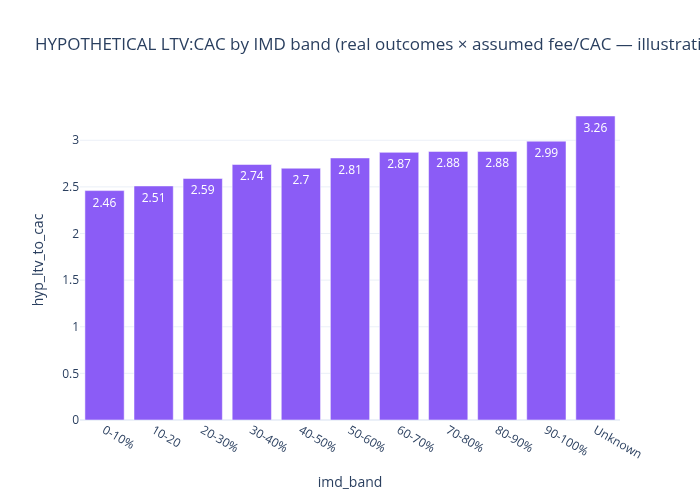

In [13]:
ue = Q['hypothetical_ltv_cac_by_imd_band']; display(ue)
fig = px.bar(ue.sort_values('imd_band'), x='imd_band', y='hyp_ltv_to_cac', text='hyp_ltv_to_cac', color_discrete_sequence=[BRAND[5]],
             title='HYPOTHETICAL LTV:CAC by IMD band (real outcomes × assumed fee/CAC — illustrative only)')
save(fig, "10_hypothetical_ltv_cac"); fig.show()

## 7. Dashboard (Power BI-style showcase built in Plotly)

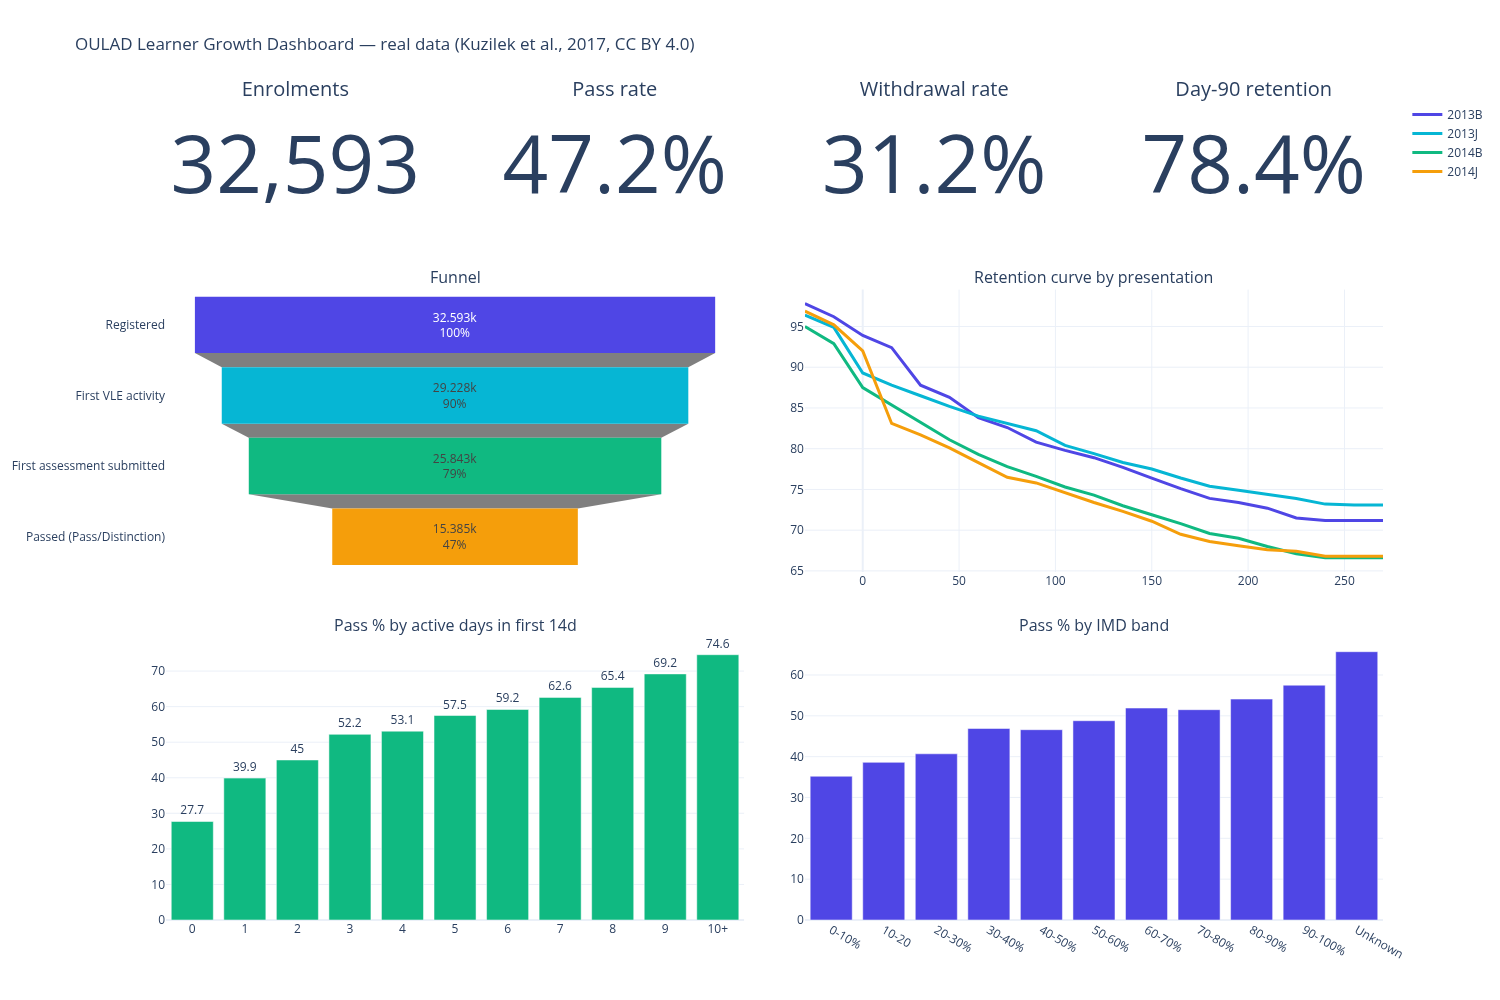

In [14]:
fig = make_subplots(rows=3, cols=4, row_heights=[0.18,0.41,0.41],
    specs=[[{"type":"indicator"}]*4, [{"type":"funnel","colspan":2},None,{"type":"xy","colspan":2},None],
           [{"type":"xy","colspan":2},None,{"type":"xy","colspan":2},None]],
    subplot_titles=["","","","","Funnel","Retention curve by presentation","Pass % by active days in first 14d","Pass % by IMD band"], vertical_spacing=0.08)
kp = [("Enrolments", len(df), ""), ("Pass rate", df.passed.mean()*100, "%"), ("Withdrawal rate", df.withdrawn.mean()*100, "%"),
      ("Day-90 retention", (df.date_unregistration.fillna(1e9) > 90).mean()*100, "%")]
for i,(t,v,u) in enumerate(kp,1):
    fig.add_trace(go.Indicator(mode="number", value=v, title={"text":t}, number={"suffix":u, "valueformat":",.1f" if u else ",.0f"}), 1, i)
fig.add_trace(go.Funnel(y=f.stage, x=f.students, textinfo="value+percent initial", marker_color=BRAND[:4], showlegend=False), 2, 1)
for j,(p,g) in enumerate(rc.groupby('code_presentation')):
    fig.add_trace(go.Scatter(x=g.day_since_start, y=g.retained_pct, name=p, mode='lines', line=dict(color=BRAND[j], width=3)), 2, 3)
fig.add_trace(go.Bar(x=mm.active_days_first_14, y=mm.pass_pct, marker_color=BRAND[2], showlegend=False, text=mm.pass_pct, textposition='outside'), 3, 1)
s = sg[sg.dimension=='imd_band'].sort_values('segment')
fig.add_trace(go.Bar(x=s.segment, y=s.pass_pct, marker_color=BRAND[0], showlegend=False), 3, 3)
fig.update_layout(title="OULAD Learner Growth Dashboard — real data (Kuzilek et al., 2017, CC BY 4.0)", height=1000, width=1500)
save(fig, "00_dashboard", w=1500, h=1000); fig.show()

## 8. Takeaways (real data)
1. The **biggest leak is submit → pass** (40.5% of submitters don't pass), not activation: 89.7% of registrants touch the VLE.
2. **Withdrawal is front-loaded**: 26.6% of withdrawals happen before the module starts and 50.9% by day 30.
3. **No single sharp "magic moment"**: pass rate climbs steadily with early active days (27.7% at 0 days → 74.6% at 10+). The biggest single step is **0 → 1 active day (+12.2 pts)**; the first assessment score crossing **60** is the sharpest threshold (33% → 57% pass).
4. **February vs October starts retain about the same** (D90 78.1% vs 78.6%); the gaps are between presentations and modules.
5. **Segments**: deprivation (IMD 0-10% 35.2% pass vs 90-100% 57.5%), prior education and repeat attempts are the strongest predictors.